

### Dataset Upload and Extraction

Matter: The dataset ZIP file is uploaded into Google Colab using `files.upload()`. The `zipfile` module extracts the dataset into the `/content/dataset` directory. The paths for X-ray images (`Model_Xrays`) and corresponding segmentation masks (`Masks`) are defined using `Path`. Finally, the code verifies that both folders exist, confirming successful dataset extraction and readiness for preprocessing and model training.


In [ ]:
from google.colab import files
import zipfile
from pathlib import Path

uploaded = files.upload()  # Select Data_Set.zip

zip_path = next(iter(uploaded.keys()))
extract_dir = Path("/content/dataset")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

DATA_DIR = extract_dir / "Data_Set"
IMAGE_DIR = DATA_DIR / "Model_Xrays"
MASK_DIR = DATA_DIR / "Masks"

print("Images folder exists:", IMAGE_DIR.exists())
print("Masks folder exists:", MASK_DIR.exists())

Saving Data_Set (1).zip to Data_Set (1) (1).zip
Images folder exists: True
Masks folder exists: True


### Step 2: Matching X-ray Images with Corresponding Masks

Matter: The code retrieves and sorts all X-ray images and segmentation masks in PNG format. It compares their filenames to ensure that each X-ray image has a corresponding mask. The output confirms that all 420 X-ray images have matching masks, with no missing or unmatched files. This verifies that the dataset is correctly organized and ready for preprocessing and model training.

In [ ]:
image_paths = sorted(IMAGE_DIR.glob("*.png"))
mask_paths = sorted(MASK_DIR.glob("*.png"))

image_names = {p.name for p in image_paths}
mask_names = {p.name for p in mask_paths}

print("Number of X-ray images:", len(image_paths))
print("Number of masks:", len(mask_paths))
print("Images without matching masks:", len(image_names - mask_names))
print("Masks without matching images:", len(mask_names - image_names))

print("\nFirst 5 image filenames:")
print([p.name for p in image_paths[:5]])

Number of X-ray images: 420
Number of masks: 420
Images without matching masks: 0
Masks without matching images: 0

First 5 image filenames:
['CHNCXR_0001_0.png', 'CHNCXR_0002_0.png', 'CHNCXR_0003_0.png', 'CHNCXR_0004_0.png', 'CHNCXR_0005_0.png']


### Step 3: Visualization of X-ray Images and Segmentation Masks



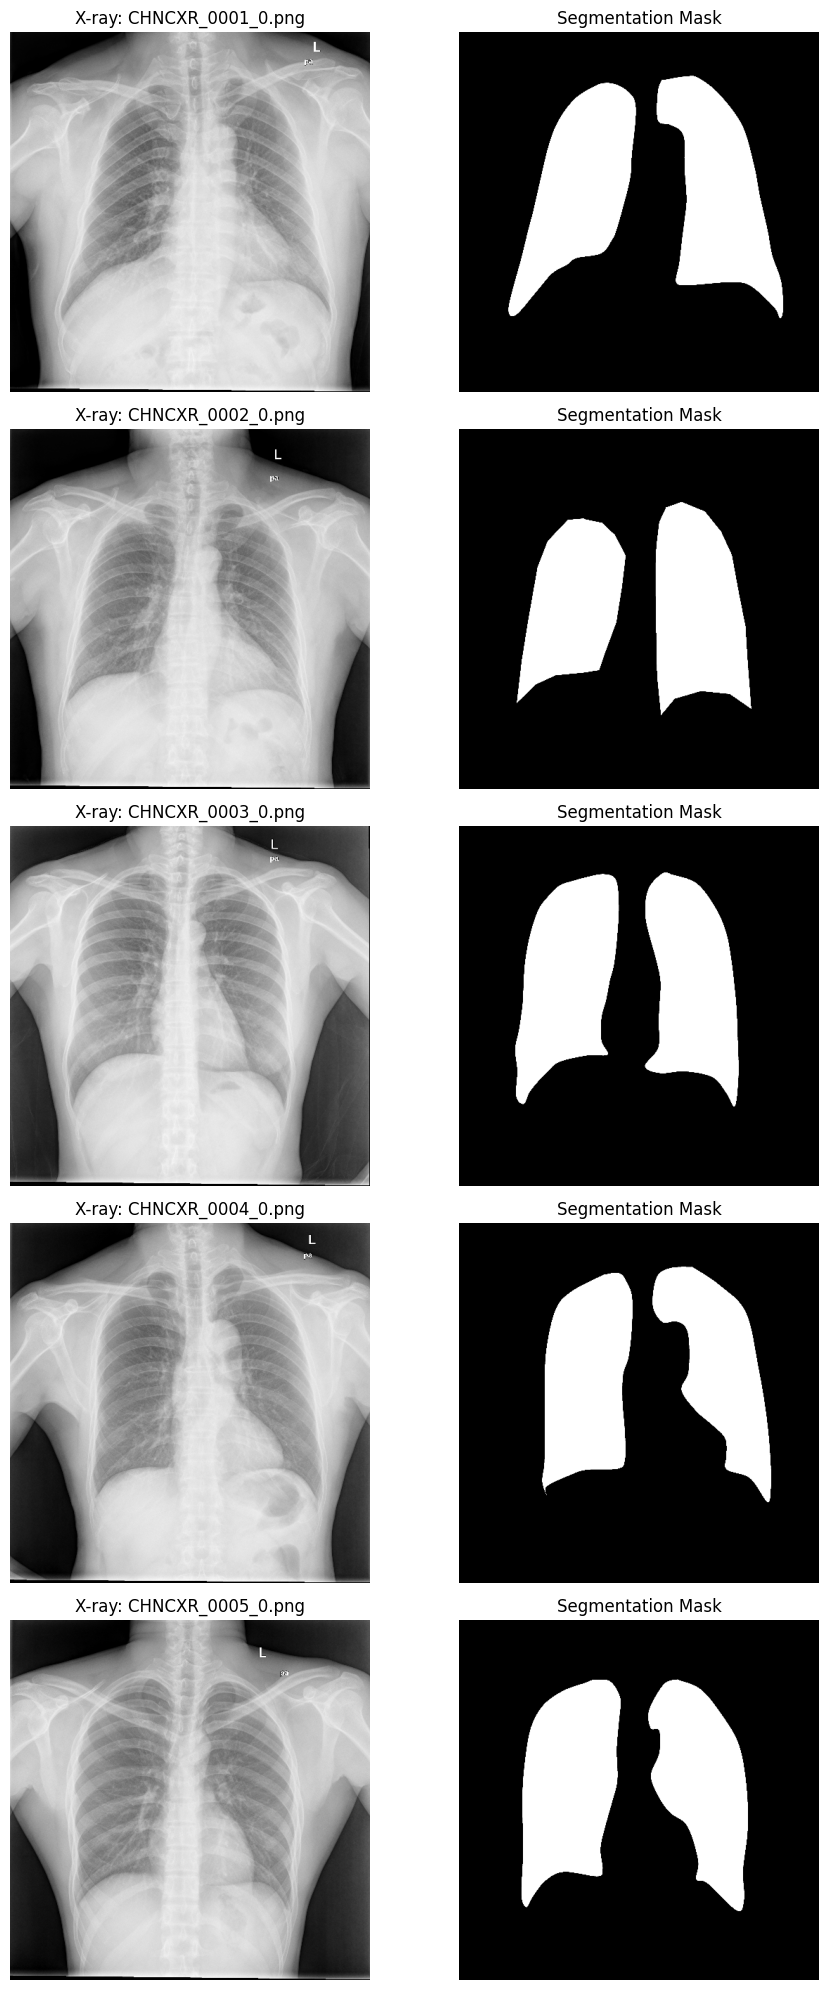

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

matched_names = sorted(image_names & mask_names)

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for i, name in enumerate(matched_names[:5]):
    image = np.array(Image.open(IMAGE_DIR / name).convert("L"))
    mask = np.array(Image.open(MASK_DIR / name).convert("L"))

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f"X-ray: {name}")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Segmentation Mask")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

The code displays the first five matched chest X-ray images along with their corresponding segmentation masks using Matplotlib. The X-ray images are converted into grayscale, while the masks highlight the lung regions in white and the background in black. This visualization helps verify the alignment between images and masks, ensuring the dataset is suitable for lung segmentation model training.

### Step 4: Checking Segmentation Mask Dimensions and Pixel Values

In [ ]:
for name in matched_names[:5]:
    mask = np.array(Image.open(MASK_DIR / name).convert("L"))

    print(
        name,
        "| Shape:", mask.shape,
        "| Unique values:", np.unique(mask)[:20]
    )

CHNCXR_0001_0.png | Shape: (512, 512) | Unique values: [ 0  1  2  4  5  6  7  8 10 12 14 15 18 20 21 22 23 24 25 26]
CHNCXR_0002_0.png | Shape: (512, 512) | Unique values: [ 0  1  2  3  4  6  7  8  9 10 11 13 14 18 19 22 23 24 25 26]
CHNCXR_0003_0.png | Shape: (512, 512) | Unique values: [ 0  1  2  3  4  6  7 10 14 15 16 20 21 23 24 26 27 28 29 30]
CHNCXR_0004_0.png | Shape: (512, 512) | Unique values: [ 0  1  2  3  5  6  7  8  9 10 11 13 14 15 16 19 20 21 22 23]
CHNCXR_0005_0.png | Shape: (512, 512) | Unique values: [ 0  1  2  3  4  5  6  7  8 10 11 12 14 18 19 22 23 24 25 26]


The code examines the first five segmentation masks to verify their dimensions and pixel values. Each mask has a shape of 512 × 512 pixels and contains multiple grayscale intensity values. This analysis helps identify whether the masks are binary or grayscale and determines the need for thresholding to convert them into binary masks (0 and 1) before training the lung segmentation model.

### Step 3: Visualization of X-ray Images and Segmentation Masks

Matter: The code displays the first five X-ray images alongside their corresponding segmentation masks using Matplotlib. The X-ray images are converted to grayscale, while the masks highlight the lung regions in white and the background in black. This visualization helps verify that the images and masks are correctly matched and that the lung regions are properly identified.


CHNCXR_0001_0.png
Mask minimum: 0
Mask maximum: 255
Unique pixel values: 164
Percentage of zero pixels: 75.38 %
Percentage of nonzero pixels: 24.62 %


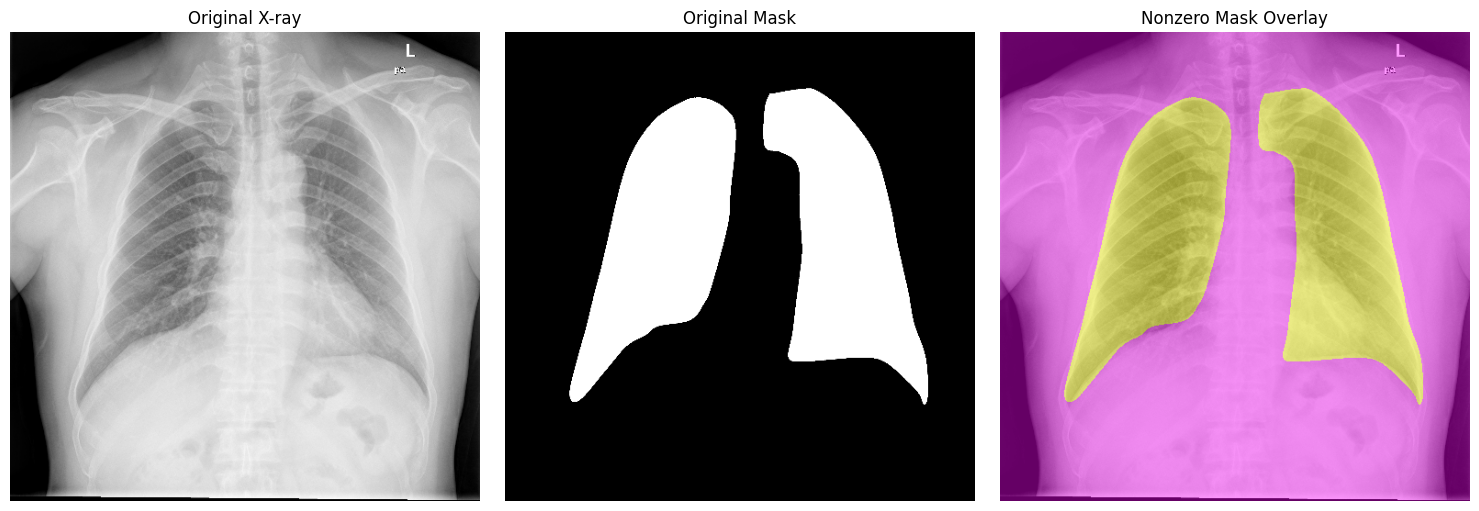


CHNCXR_0002_0.png
Mask minimum: 0
Mask maximum: 255
Unique pixel values: 132
Percentage of zero pixels: 78.26 %
Percentage of nonzero pixels: 21.74 %


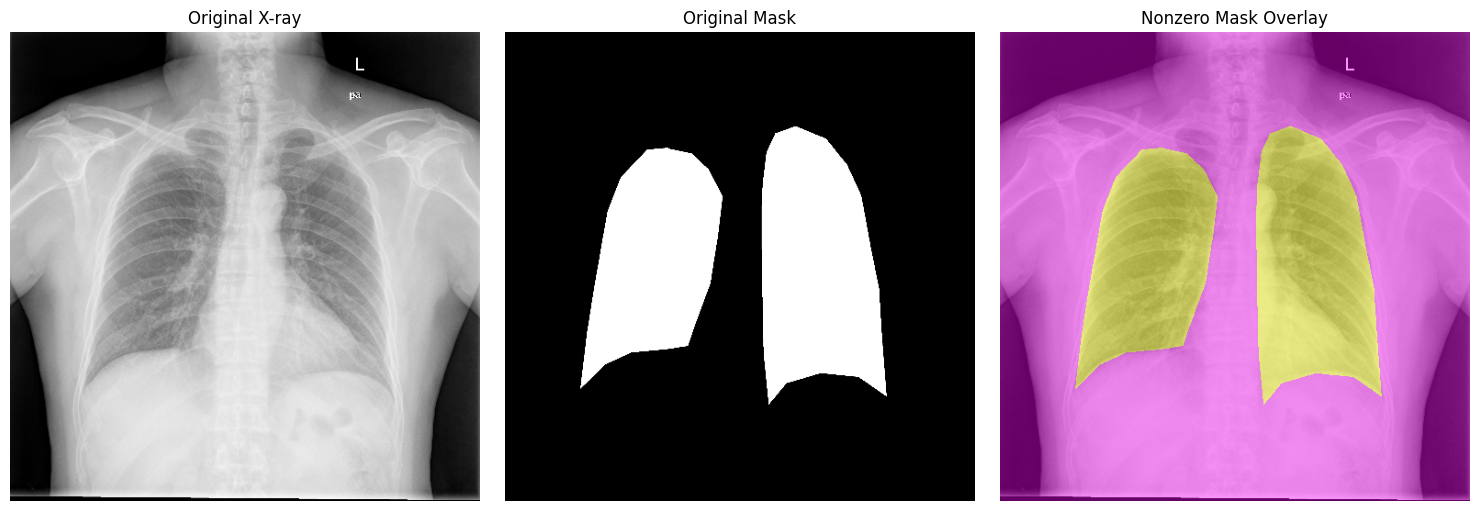


CHNCXR_0003_0.png
Mask minimum: 0
Mask maximum: 255
Unique pixel values: 157
Percentage of zero pixels: 76.01 %
Percentage of nonzero pixels: 23.99 %


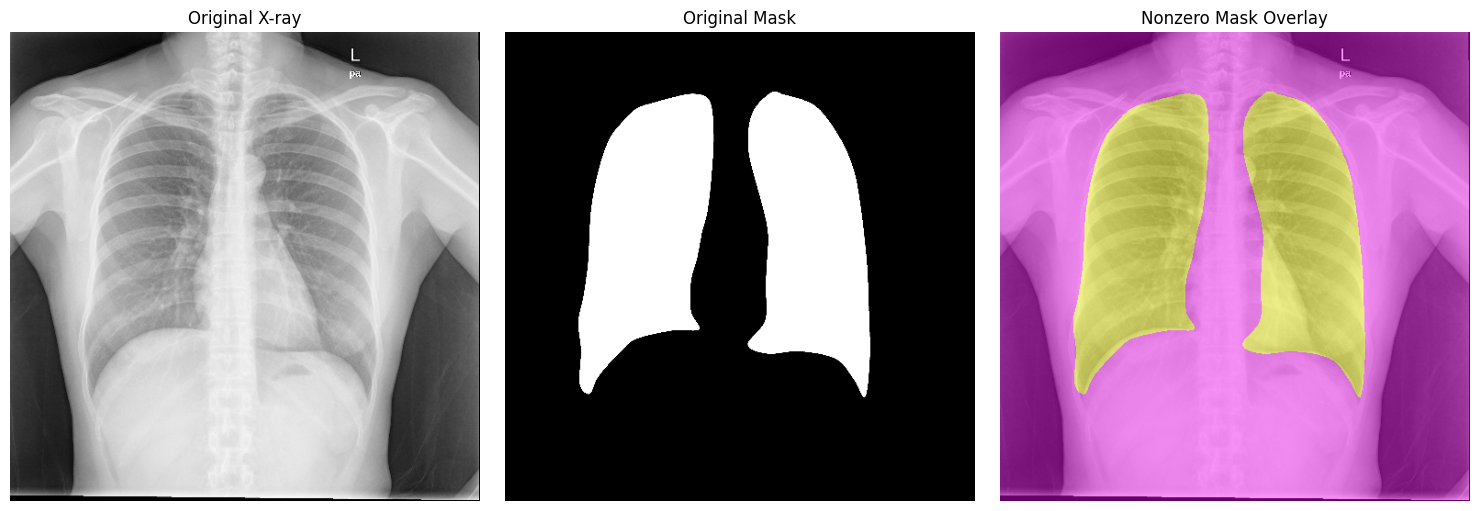

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

for name in matched_names[:3]:
    image = np.array(
        Image.open(IMAGE_DIR / name).convert("L")
    )
    mask = np.array(
        Image.open(MASK_DIR / name).convert("L")
    )

    print(f"\n{name}")
    print("Mask minimum:", mask.min())
    print("Mask maximum:", mask.max())
    print("Unique pixel values:", len(np.unique(mask)))
    print("Percentage of zero pixels:",
          round(np.mean(mask == 0) * 100, 2), "%")
    print("Percentage of nonzero pixels:",
          round(np.mean(mask > 0) * 100, 2), "%")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Original X-ray")

    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Original Mask")

    axes[2].imshow(image, cmap="gray")
    axes[2].imshow(mask > 0, cmap="spring", alpha=0.4)
    axes[2].set_title("Nonzero Mask Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

The code analyzes the pixel values of segmentation masks to understand their structure. The pixel values range from 0 to 255, where 0 represents the background and 255 represents the lung regions. The results show that approximately 22–25% of pixels are nonzero, while the remaining pixels represent the background. Intermediate pixel values indicate that the masks are not strictly binary, so thresholding is required before model training.

In [ ]:
import numpy as np
from PIL import Image

# Create mappings from file name to full path
image_map = {p.name: p for p in IMAGE_DIR.glob("*.png")}
mask_map = {p.name: p for p in MASK_DIR.glob("*.png")}

for name in matched_names[:3]:
    mask = np.array(Image.open(mask_map[name]).convert("L"))

    print(
        name,
        "Min:", mask.min(),
        "Max:", mask.max(),
        "Unique values:", len(np.unique(mask)),
        "Values at percentiles:",
        np.percentile(mask, [0, 25, 50, 75, 90, 99, 100])
    )

CHNCXR_0001_0.png Min: 0 Max: 255 Unique values: 164 Values at percentiles: [  0.   0.   0.   0. 255. 255. 255.]
CHNCXR_0002_0.png Min: 0 Max: 255 Unique values: 132 Values at percentiles: [  0.   0.   0.   0. 255. 255. 255.]
CHNCXR_0003_0.png Min: 0 Max: 255 Unique values: 157 Values at percentiles: [  0.   0.   0.   0. 255. 255. 255.]


We'll use 256 × 256 initially to reduce memory requirements. X-ray images use bilinear interpolation, while masks use nearest-neighbor interpolation to preserve label boundaries.

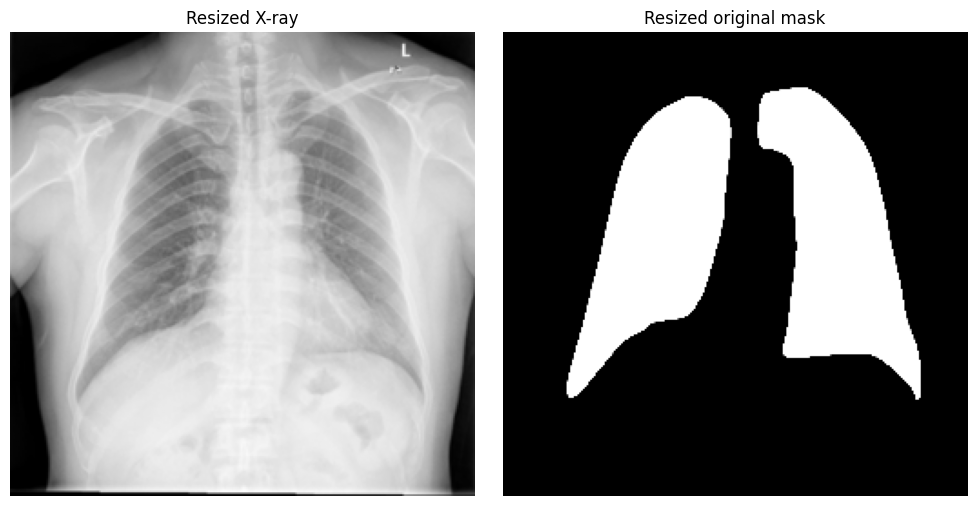

In [ ]:
import matplotlib.pyplot as plt

IMG_SIZE = 256

def preprocess_pair(name):
    # Preprocess X-ray
    image = Image.open(image_map[name]).convert("L")
    image = image.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.BILINEAR
    )
    image = np.asarray(image, dtype=np.float32)

    # Preprocess mask
    mask = Image.open(mask_map[name]).convert("L")
    mask = mask.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.NEAREST
    )
    mask = np.asarray(mask, dtype=np.uint8)

    return image, mask

image, mask = preprocess_pair(matched_names[0])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Resized X-ray")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Resized original mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

For a lung segmentation model, the target mask should contain only background and lung labels. Based on your visualization, start with a threshold of 127 and inspect the result.

Binary mask values: [0 1]
Lung pixel percentage: 24.55291748046875


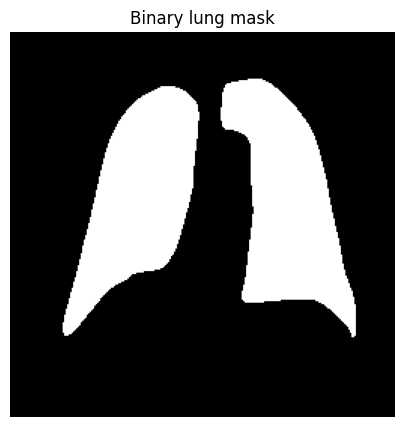

In [ ]:
binary_mask = (mask > 127).astype(np.uint8)

print("Binary mask values:", np.unique(binary_mask))
print("Lung pixel percentage:", binary_mask.mean() * 100)

plt.figure(figsize=(5, 5))
plt.imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
plt.title("Binary lung mask")
plt.axis("off")
plt.show()

Normalize the X-rays to the range 0–1. Keep the masks binary.

In [ ]:
import cv2, numpy as np
from sklearn.model_selection import train_test_split

IMG_SIZE = 256
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def prep(gray_u8):
    """uint8 grayscale -> resized, contrast-equalized, standardized float32"""
    x = cv2.resize(gray_u8, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    x = clahe.apply(x).astype(np.float32)
    return (x - x.mean()) / (x.std() + 1e-6)

X, Y = [], []
for n in matched_names:
    img = cv2.imread(str(image_map[n]), cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(str(mask_map[n]), cv2.IMREAD_GRAYSCALE)
    msk = cv2.resize(msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    X.append(prep(img)); Y.append((msk > 127).astype(np.float32))
X = np.array(X)[..., None]; Y = np.array(Y)[..., None]

X_train, X_tmp, Y_train, Y_tmp = train_test_split(X, Y, test_size=0.30, random_state=42)
X_val, X_test, Y_val, Y_test   = train_test_split(X_tmp, Y_tmp, test_size=0.50, random_state=42)


### Step 7: Visualization of Preprocessed X-ray Images and Binary Masks


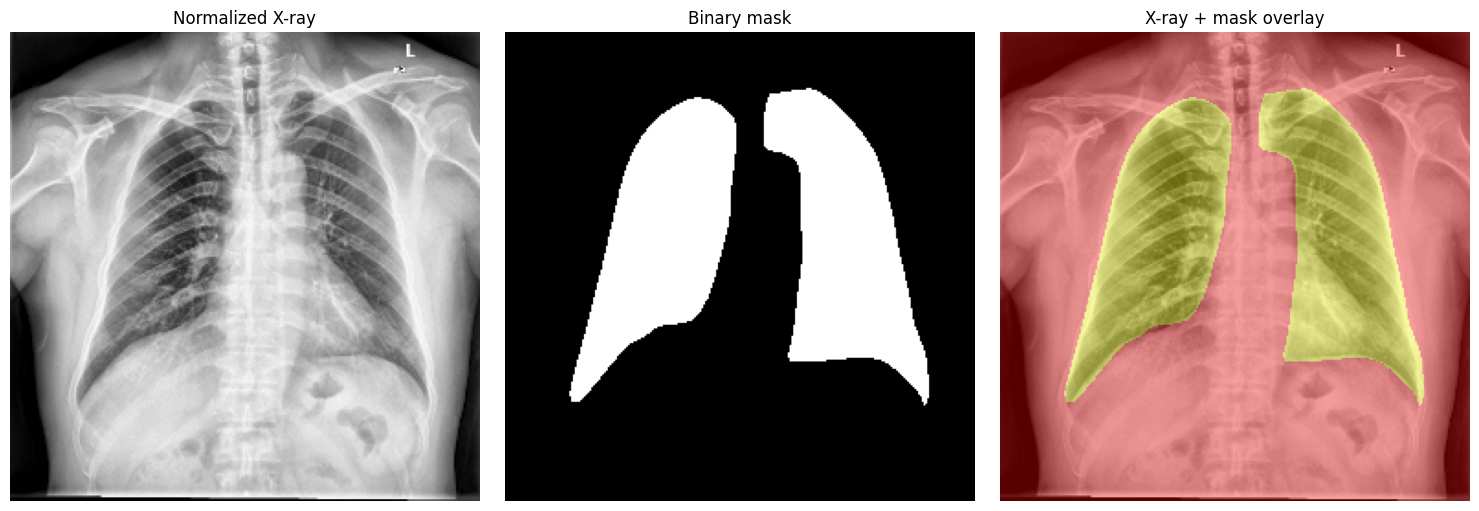

In [ ]:
i = 0

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(X[i, :, :, 0], cmap="gray")
axes[0].set_title("Normalized X-ray")

axes[1].imshow(Y[i, :, :, 0], cmap="gray")
axes[1].set_title("Binary mask")

axes[2].imshow(X[i, :, :, 0], cmap="gray")
axes[2].imshow(Y[i, :, :, 0], cmap="autumn", alpha=0.35)
axes[2].set_title("X-ray + mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

 The code visualizes the normalized X-ray image, its corresponding binary segmentation mask, and the mask overlay using Matplotlib. The normalized X-ray displays the enhanced lung structure, while the binary mask highlights the lung regions in white against a black background. The overlay combines the X-ray and mask using transparency (`alpha=0.35`) to show the segmented lung regions. This helps verify the accuracy of mask alignment and ensures the preprocessed data is suitable for U-Net model training.

### Step 8: TensorFlow Initialization and GPU Availability Check


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


The code imports TensorFlow and the required Keras modules for building the U-Net segmentation model. It checks the installed TensorFlow version and verifies GPU availability. The output confirms that TensorFlow 2.21.0 is installed and a GPU is successfully detected, enabling faster model training and efficient deep learning computations.

### Step 9: Building the U-Net Model for Lung Segmentation


In [ ]:
def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)

    return x


def build_unet(input_shape=(256, 256, 1)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    c5 = conv_block(p4, 512)

    # Decoder
    u6 = layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(c5)
    u6 = layers.Concatenate()([u6, c4])
    c6 = conv_block(u6, 256)

    u7 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c6)
    u7 = layers.Concatenate()([u7, c3])
    c7 = conv_block(u7, 128)

    u8 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c7)
    u8 = layers.Concatenate()([u8, c2])
    c8 = conv_block(u8, 64)

    u9 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c8)
    u9 = layers.Concatenate()([u9, c1])
    c9 = conv_block(u9, 32)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c9)

    return Model(inputs, outputs, name="Lung_UNet")


model = build_unet()
model.summary()

Model: "Lung_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_2[

 Total params: 7,771,297 (29.65 MB)

 Trainable params: 7,765,409 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

The code builds a U-Net model using TensorFlow and Keras to identify lung regions in chest X-ray images. The encoder extracts important image features, the bottleneck learns deeper patterns, and the decoder reconstructs the lung segmentation mask. Skip connections help preserve image details. The model takes a 256 × 256 grayscale image as input and produces a binary lung mask using sigmoid activation. The model contains approximately 7.77 million parameters and is ready for training.

### Step 10: Defining Loss Functions, Evaluation Metrics, and Model Compilation


In [ ]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = [1, 2, 3]

    intersection = tf.reduce_sum(
        y_true * y_pred, axis=axes
    )

    denominator = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
    )

    dice = (
        2.0 * intersection + smooth
    ) / (denominator + smooth)

    return tf.reduce_mean(1.0 - dice)


def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(
        y_true, y_pred
    )
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


def dice_metric(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(
        tf.cast(y_true, tf.float32), [-1]
    )
    y_pred_f = tf.reshape(
        tf.cast(y_pred >= 0.5, tf.float32), [-1]
    )

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true_f)
        + tf.reduce_sum(y_pred_f)
        + smooth
    )


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=[
        dice_metric,
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1], threshold=0.5
        )
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


The code defines Dice Loss and Binary Cross-Entropy (BCE) to measure segmentation errors during training. Both losses are combined to improve lung segmentation accuracy. The Dice coefficient and Binary IoU are used to evaluate how well the predicted lung regions match the actual masks. The model is compiled using the Adam optimizer with a learning rate of 0.001. Finally, the model is successfully compiled and ready for training.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
AUTOTUNE = tf.data.AUTOTUNE

# geometry: applied to image+mask stacked as 2 channels so they stay aligned
geo = tf.keras.Sequential([
    layers.RandomRotation(0.08, fill_mode="constant"),
    layers.RandomZoom((-0.25, 0.25), fill_mode="constant"),   # zoom in/out: handles tight crops
    layers.RandomTranslation(0.10, 0.10, fill_mode="constant"),
])

def augment(img, msk):
    both = geo(tf.concat([img, msk], -1)[None], training=True)[0]
    img, msk = both[..., :1], tf.cast(both[..., 1:] > 0.5, tf.float32)
    # intensity: image only
    img = img * tf.random.uniform((), 0.8, 1.2) + tf.random.uniform((), -0.3, 0.3)  # contrast / brightness
    img = img + tf.random.normal(tf.shape(img), 0, 0.05)                              # noise
    return img, msk

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, Y_train))
            .shuffle(len(X_train)).map(augment, AUTOTUNE).batch(8).prefetch(AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, Y_val)).batch(8)


### Step 11: U-Net Model Training and Performance Evaluation


In [ ]:
tf.keras.backend.clear_session()
model = build_unet((IMG_SIZE, IMG_SIZE, 1))
model.compile(tf.keras.optimizers.Adam(3e-4), loss=combined_loss,
              metrics=[dice_metric])

model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=[
    tf.keras.callbacks.ModelCheckpoint("/content/lung_unet_v2.keras", monitor="val_dice_metric",
                                       mode="max", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
])

# no early stopping, so load the best epoch (not the last one)
model = tf.keras.models.load_model(
    "/content/lung_unet_v2.keras",
    custom_objects={"combined_loss": combined_loss, "dice_loss": dice_loss, "dice_metric": dice_metric})

print("Test:", model.evaluate(X_test, Y_test, return_dict=True))

Epoch 1/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 48s 720ms/step - dice_metric: 0.8151 - loss: 0.6079 - val_dice_metric: 7.3957e-12 - val_loss: 1.2659 - learning_rate: 3.0000e-04
Epoch 2/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 334ms/step - dice_metric: 0.9286 - loss: 0.2520 - val_dice_metric: 7.3964e-12 - val_loss: 1.4525 - learning_rate: 3.0000e-04
Epoch 3/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 312ms/step - dice_metric: 0.9433 - loss: 0.1981 - val_dice_metric: 7.3964e-12 - val_loss: 1.7913 - learning_rate: 3.0000e-04
Epoch 4/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 332ms/step - dice_metric: 0.9503 - loss: 0.1730 - val_dice_metric: 0.0061 - val_loss: 1.7924 - learning_rate: 3.0000e-04
Epoch 5/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 323ms/step - dice_metric: 0.9516 - loss: 0.1626 - val_dice_metric: 0.5120 - val_loss: 1.0224 - learning_rate: 3.0000e-04
Epoch 6/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 311ms/step - dice_metric: 0.9581 - loss: 0.1383 - val_dice_metric: 0.1133 - val_loss: 1.7189 - learning_rate: 3.0000e-04
Epoch 7/60

The code trains the U-Net model for 60 epochs using the Adam optimizer with a learning rate of 0.0003. ModelCheckpoint saves the best model based on validation Dice score, while ReduceLROnPlateau reduces the learning rate when validation loss stops improving. After training, the best model is loaded and evaluated on the test dataset. The model achieves a Dice score of 97.31% and a test loss of 0.0770, showing strong performance in lung segmentation.


Epoch 1/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 52s 777ms/step - dice_metric: 0.7960 - loss: 0.6558 - val_dice_metric: 7.3964e-12 - val_loss: 1.3232 - learning_rate: 3.0000e-04
Epoch 2/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 307ms/step - dice_metric: 0.9226 - loss: 0.2904 - val_dice_metric: 7.3964e-12 - val_loss: 1.4595 - learning_rate: 3.0000e-04
Epoch 3/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 303ms/step - dice_metric: 0.9419 - loss: 0.2176 - val_dice_metric: 7.3964e-12 - val_loss: 1.6183 - learning_rate: 3.0000e-04
Epoch 4/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 332ms/step - dice_metric: 0.9505 - loss: 0.1834 - val_dice_metric: 2.9131e-04 - val_loss: 1.7001 - learning_rate: 3.0000e-04
Epoch 5/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 13s 341ms/step - dice_metric: 0.9484 - loss: 0.1816 - val_dice_metric: 0.4103 - val_loss: 1.0301 - learning_rate: 3.0000e-04
Epoch 6/60
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 328ms/step - dice_metric: 0.9565 - loss: 0.1555 - val_dice_metric: 0.6454 - val_loss: 0.8262 - learning_rate: 3.0000e-04
Epoch 

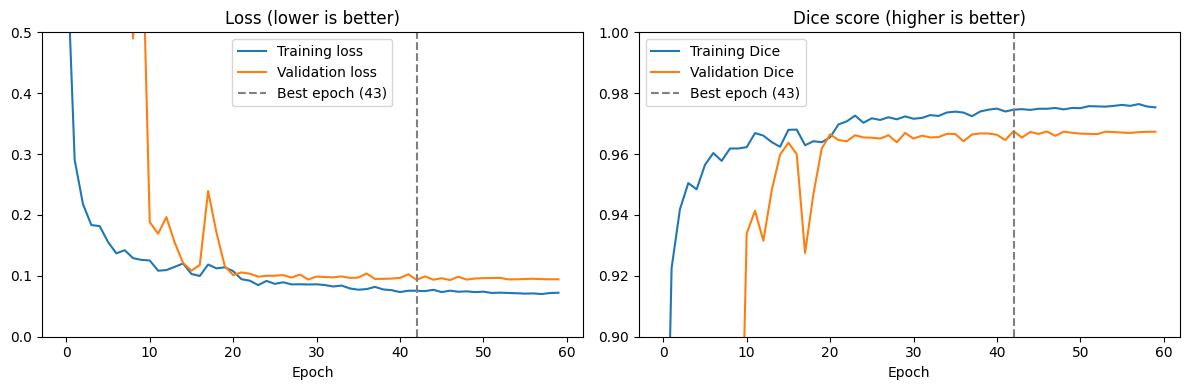

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - dice_metric: 0.9747 - loss: 0.0718
Test: {'dice_metric': 0.9747329354286194, 'loss': 0.07176578789949417}


In [ ]:
tf.keras.backend.clear_session()
model = build_unet((IMG_SIZE, IMG_SIZE, 1))
model.compile(tf.keras.optimizers.Adam(3e-4), loss=combined_loss,
              metrics=[dice_metric])

history = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=[
    tf.keras.callbacks.ModelCheckpoint("/content/lung_unet_v2.keras", monitor="val_dice_metric",
                                       mode="max", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
])

# graph: training vs validation
import matplotlib.pyplot as plt
h = history.history
best = int(np.argmax(h["val_dice_metric"]))          # best epoch (starts from 0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(h["loss"], label="Training loss")
ax[0].plot(h["val_loss"], label="Validation loss")
ax[0].axvline(best, color="gray", linestyle="--", label=f"Best epoch ({best + 1})")
ax[0].set_ylim(0, 0.5)
ax[0].set_title("Loss (lower is better)")
ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(h["dice_metric"], label="Training Dice")
ax[1].plot(h["val_dice_metric"], label="Validation Dice")
ax[1].axvline(best, color="gray", linestyle="--", label=f"Best epoch ({best + 1})")
ax[1].set_ylim(0.9, 1.0)
ax[1].set_title("Dice score (higher is better)")
ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.tight_layout()
plt.show()

# no early stopping, so load the best epoch (not the last one)
model = tf.keras.models.load_model(
    "/content/lung_unet_v2.keras",
    custom_objects={"combined_loss": combined_loss, "dice_loss": dice_loss, "dice_metric": dice_metric})

print("Test:", model.evaluate(X_test, Y_test, return_dict=True))

The U-Net model is trained for 60 epochs using the Adam optimizer with a learning rate of 0.0003. The model performance is monitored using Dice score and validation loss. The learning rate is automatically reduced when validation loss stops improving, and the best model is saved for testing. After training, the model achieves a test Dice score of 97.47% and a test loss of 0.0718, demonstrating strong performance in segmenting lung regions from chest X-ray images.

### Step 12: Lung Segmentation Prediction and Post-Processing

In [ ]:
from scipy import ndimage as ndi

def predict_prob(model, x):                       # x: (N,256,256,1)
    p1 = model.predict(x, verbose=0)
    p2 = model.predict(x[:, :, ::-1], verbose=0)[:, :, ::-1]
    return (p1 + p2)[..., 0] / 2

def postprocess(prob, thr=0.5):
    m = prob >= thr
    m = ndi.binary_opening(m, iterations=2)       # remove small specks
    m = ndi.binary_closing(m, iterations=3)       # join broken pieces
    m = ndi.binary_fill_holes(m)                  # fill holes inside lungs
    lab, n = ndi.label(m)
    if n == 0: return m.astype(np.uint8)
    sizes = ndi.sum(m, lab, range(1, n + 1))
    keep = np.argsort(sizes)[-2:] + 1             # keep only the 2 biggest blobs = 2 lungs
    return np.isin(lab, keep).astype(np.uint8)


Step 13: Lung Segmentation Prediction and Result Visualization

Saving JPCLN117.png to JPCLN117.png


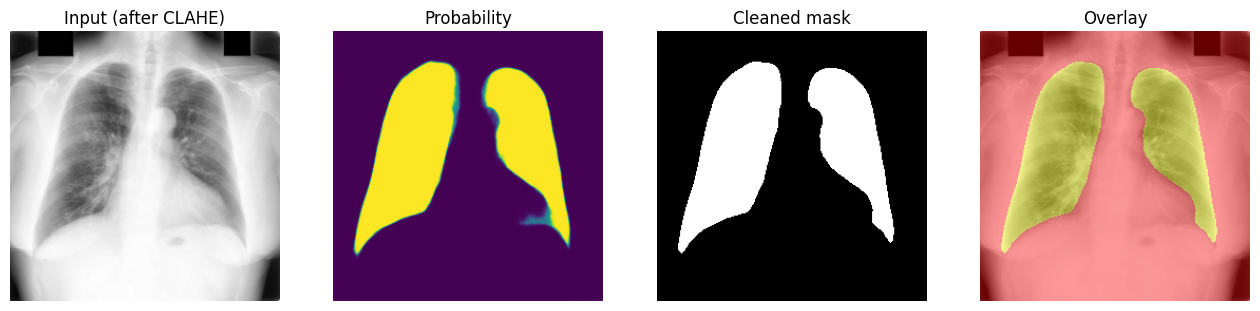

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

up = files.upload()
for name, content in up.items():
    g = cv2.imdecode(np.frombuffer(content, np.uint8), cv2.IMREAD_GRAYSCALE)
    x = prep(g)[None, ..., None]
    prob = predict_prob(model, x)[0]
    mask = postprocess(prob)

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    ax[0].imshow(x[0, ..., 0], cmap="gray");            ax[0].set_title("Input (after CLAHE)")
    ax[1].imshow(prob, cmap="viridis", vmin=0, vmax=1); ax[1].set_title("Probability")
    ax[2].imshow(mask, cmap="gray");                    ax[2].set_title("Cleaned mask")
    ax[3].imshow(x[0, ..., 0], cmap="gray"); ax[3].imshow(mask, cmap="autumn", alpha=.4)
    ax[3].set_title("Overlay")
    for a in ax: a.axis("off")
    plt.show()


The output displays the final lung segmentation results using the trained U-Net model. The input X-ray is enhanced using CLAHE, and the probability map highlights the predicted lung regions. The cleaned binary mask shows the segmented lungs in white against a black background after removing noise. Finally, the overlay highlights the lung regions on the original X-ray, demonstrating the model's ability to identify and segment lung boundaries

### Step 15: Learning Rate Optimization Using Early Stopping


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

best_dice = 0

for lr in [1e-3, 3e-4, 1e-4]:                      # learning rates to try
    m = build_unet((IMG_SIZE, IMG_SIZE, 1))
    m.compile(tf.keras.optimizers.Adam(lr), loss=combined_loss, metrics=[dice_metric])

    h = m.fit(train_ds, validation_data=val_ds, epochs=30, verbose=0,
              callbacks=[EarlyStopping(monitor="val_dice_metric", mode="max",
                                       patience=8, restore_best_weights=True)])

    d = max(h.history["val_dice_metric"])           # best validation Dice
    print(f"learning rate {lr}: val Dice = {d:.4f}")

    if d > best_dice:                               # keep the best one
        best_dice, best_lr, model = d, lr, m

print("Best learning rate:", best_lr, "| val Dice:", round(best_dice, 4))
print("Test:", model.evaluate(X_test, Y_test, return_dict=True))

learning rate 0.001: val Dice = 0.9681
learning rate 0.0003: val Dice = 0.9672
learning rate 0.0001: val Dice = 0.9667
Best learning rate: 0.001 | val Dice: 0.9681
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - dice_metric: 0.9728 - loss: 0.0781
Test: {'dice_metric': 0.9728119969367981, 'loss': 0.0781383216381073}


The code tests three learning rates (0.001, 0.0003, and 0.0001) to find the best learning rate for the U-Net model. Early Stopping is used to stop training when the validation Dice score does not improve for 8 epochs. The model with the highest validation Dice score is selected for testing. The best learning rate is 0.001, achieving a validation Dice score of 96.81%, a test Dice score of 97.28%, and a test loss of 0.0781, showing strong lung segmentation performance.

### Step 16: Multiple X-ray Image Prediction and Lung Mask Visualization


Saving JPCLN037.png to JPCLN037.png
Saving JPCLN038.png to JPCLN038.png
Saving JPCLN039.png to JPCLN039.png
Saving JPCLN040.png to JPCLN040.png
Saving JPCLN041.png to JPCLN041.png
Saving JPCLN042.png to JPCLN042.png
Saving JPCLN043.png to JPCLN043.png
Saving JPCLN044.png to JPCLN044.png
Saving JPCLN045.png to JPCLN045.png
Saving JPCLN046.png to JPCLN046.png


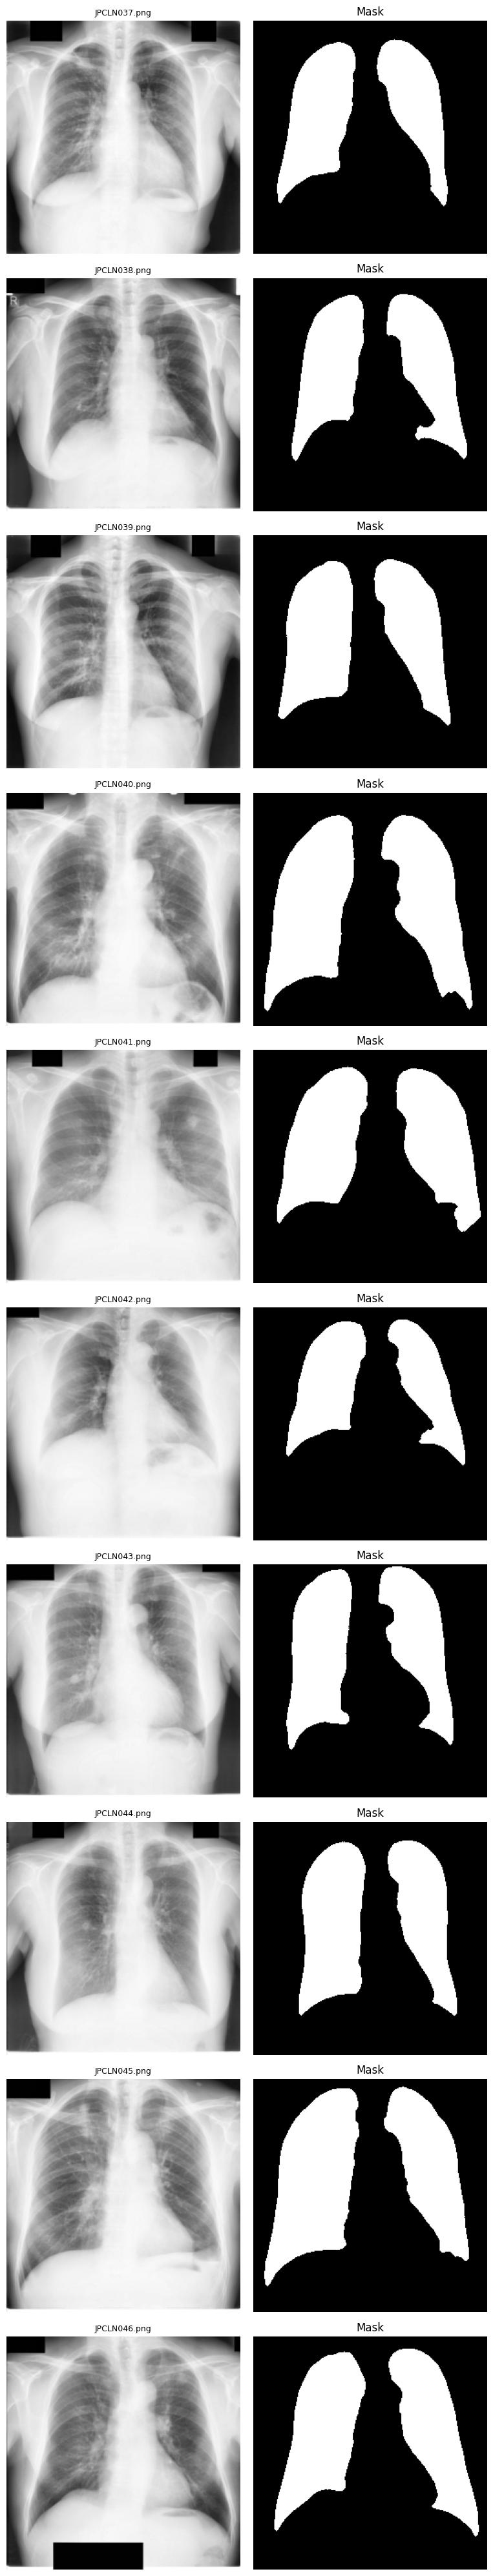

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

up = files.upload()                      # select all images at once
names = list(up.keys())

# 1. load and prepare every image
x = np.array([prep(cv2.imdecode(np.frombuffer(up[n], np.uint8), cv2.IMREAD_GRAYSCALE))
              for n in names])[..., None]

# 2. predict and clean
probs = predict_prob(model, x)
masks = np.array([postprocess(p) for p in probs])

# 3. show X-ray (left) and its mask (right) for each image
fig, axes = plt.subplots(len(names), 2, figsize=(8, 4 * len(names)))
axes = np.atleast_2d(axes)
for i in range(len(names)):
    axes[i, 0].imshow(x[i, ..., 0], cmap="gray")
    axes[i, 0].set_title(names[i][:20], fontsize=9)
    axes[i, 1].imshow(masks[i], cmap="gray")
    axes[i, 1].set_title("Mask")
    axes[i, 0].axis("off"); axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

The code allows users to upload multiple chest X-ray images at once and preprocesses them using CLAHE. The trained U-Net model predicts the lung regions for all uploaded images, and post-processing removes unwanted noise to generate clean binary masks. Finally, each X-ray image and its corresponding predicted lung mask are displayed side by side using Matplotlib, allowing easy comparison of the segmentation results.

In [ ]:
import os, io
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from google.colab import files

def upload_no_save():
    up = files.upload()                      # Colab makes a temporary copy...
    for f in up:                             # ...delete it straight away
        if os.path.exists(f):
            os.remove(f)
    return up                                # files stay in memory only

Saving JPCLN037.png to JPCLN037 (1).png
Saving JPCLN038.png to JPCLN038 (1).png
Saving JPCLN039.png to JPCLN039 (1).png
Saving JPCLN040.png to JPCLN040 (1).png
Saving JPCLN041.png to JPCLN041 (1).png
Saving JPCLN042.png to JPCLN042 (1).png
Saving JPCLN043.png to JPCLN043 (1).png
Saving JPCLN044.png to JPCLN044 (1).png
Saving JPCLN045.png to JPCLN045 (1).png
Saving JPCLN046.png to JPCLN046 (1).png


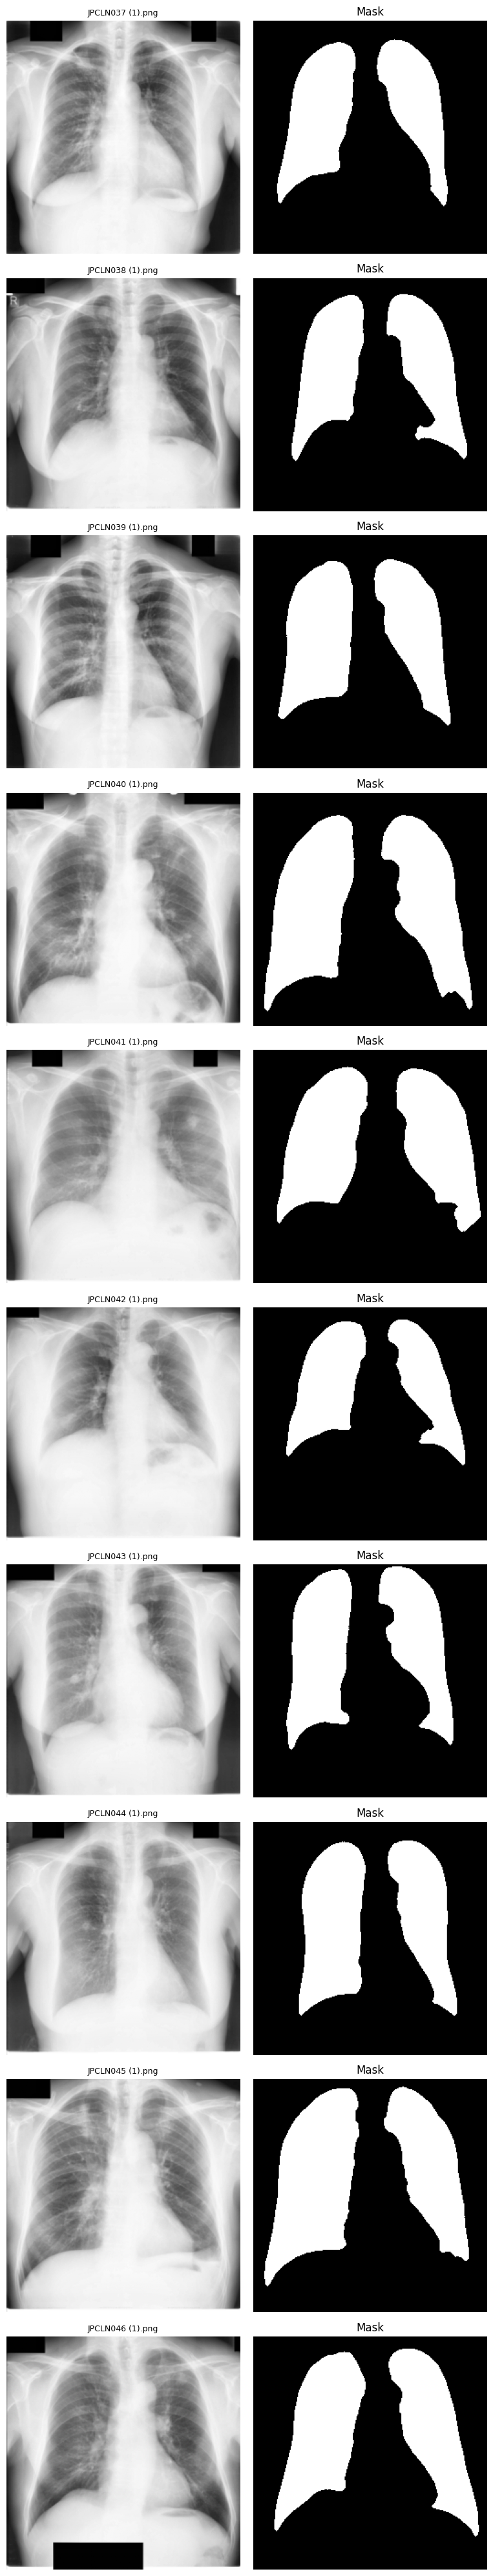

In [ ]:
up = upload_no_save()                        # select all X-ray images
names = list(up.keys())

x = np.array([prep(cv2.imdecode(np.frombuffer(up[n], np.uint8), cv2.IMREAD_GRAYSCALE))
              for n in names])[..., None]

probs = predict_prob(model, x)
masks = np.array([postprocess(p) for p in probs])

fig, axes = plt.subplots(len(names), 2, figsize=(8, 4 * len(names)))
axes = np.atleast_2d(axes)
for i in range(len(names)):
    axes[i, 0].imshow(x[i, ..., 0], cmap="gray"); axes[i, 0].set_title(names[i][:20], fontsize=9)
    axes[i, 1].imshow(masks[i], cmap="gray");     axes[i, 1].set_title("Mask")
    axes[i, 0].axis("off"); axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

Evaluation of Predicted Lung Masks Using Dice and IoU

Saving JPCLN037.png to JPCLN037 (1).png
Saving JPCLN038.png to JPCLN038 (1).png
Saving JPCLN039.png to JPCLN039 (1).png
Saving JPCLN040.png to JPCLN040 (1).png
Saving JPCLN041.png to JPCLN041 (1).png
Saving JPCLN042.png to JPCLN042 (1).png
Saving JPCLN043.png to JPCLN043 (1).png
Saving JPCLN044.png to JPCLN044 (1).png
Saving JPCLN045.png to JPCLN045 (1).png
Saving JPCLN046.png to JPCLN046 (1).png
           image   Dice    IoU
JPCLN037 (1).png 0.9787 0.9582
JPCLN038 (1).png 0.9701 0.9419
JPCLN039 (1).png 0.9801 0.9610
JPCLN040 (1).png 0.9751 0.9514
JPCLN041 (1).png 0.9580 0.9194
JPCLN042 (1).png 0.9725 0.9464
JPCLN043 (1).png 0.9700 0.9418
JPCLN044 (1).png 0.9739 0.9491
JPCLN045 (1).png 0.9735 0.9485
JPCLN046 (1).png 0.9783 0.9575

Mean Dice: 0.973 | Mean IoU: 0.9475


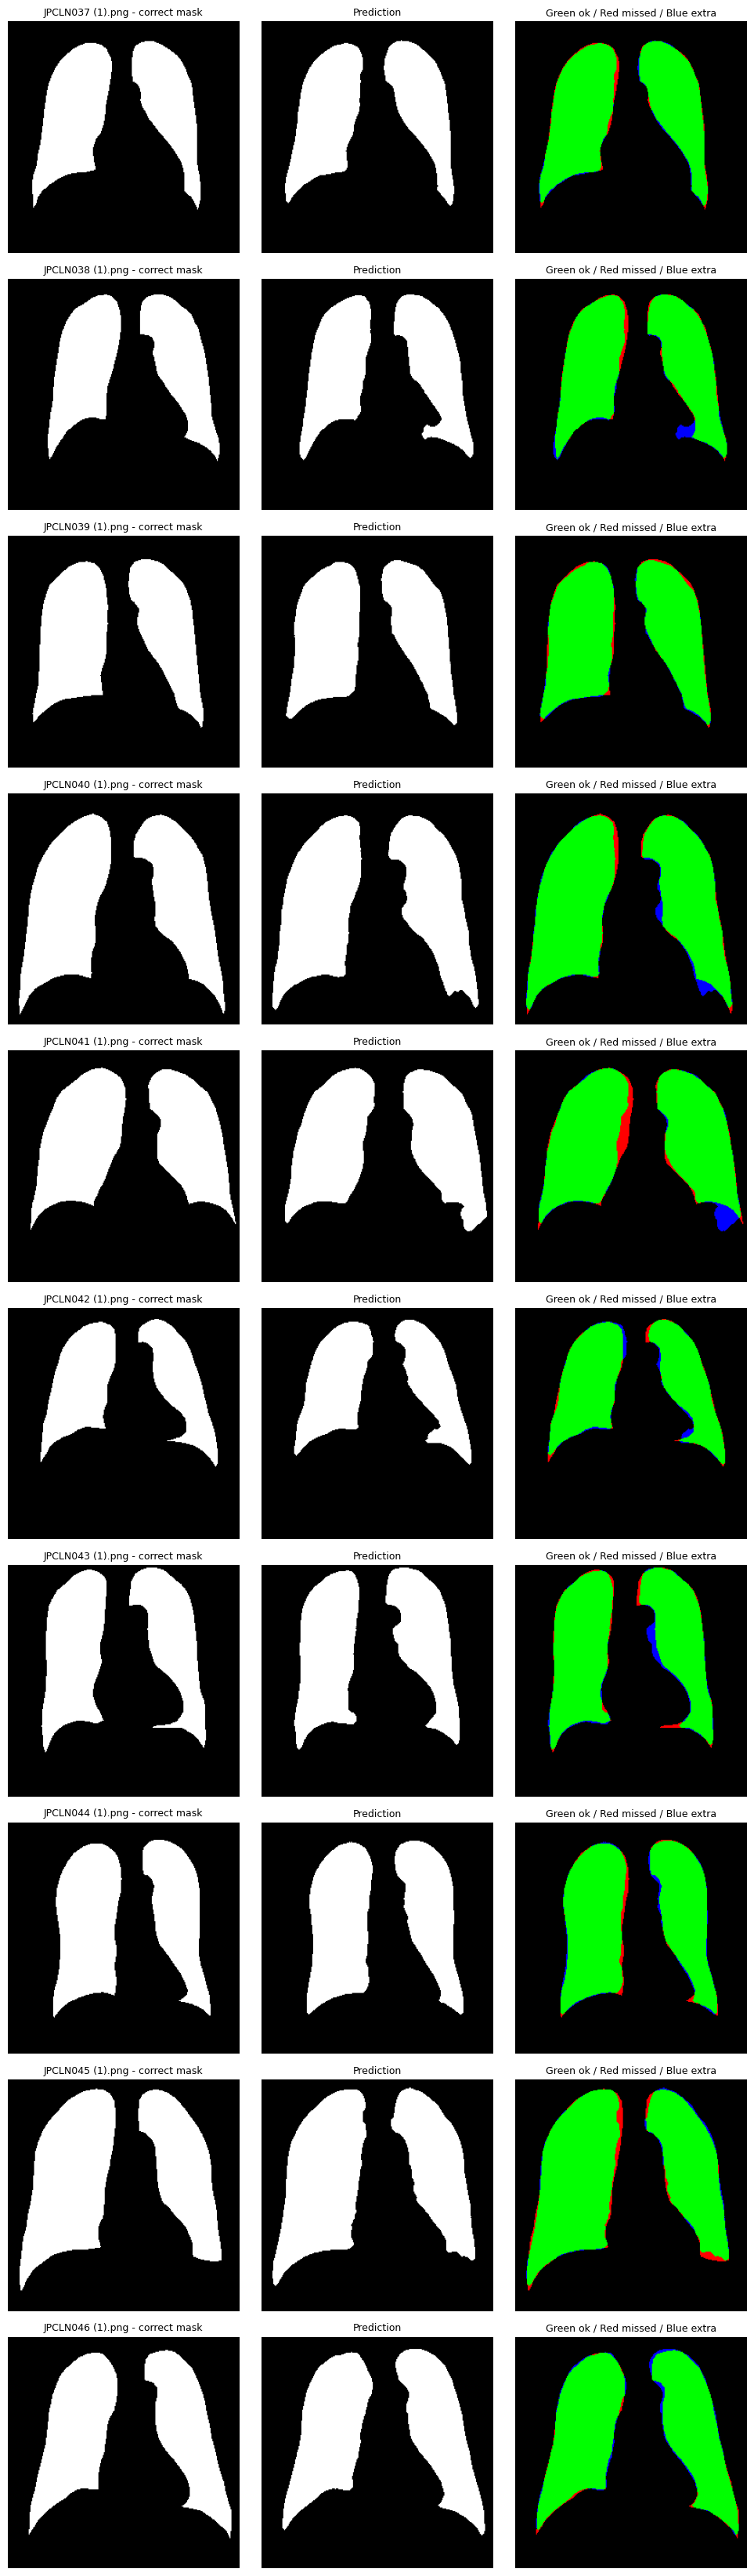

In [ ]:
gt_up = upload_no_save()                     # select the correct mask images
stem = lambda s: os.path.splitext(s)[0]      # file name without .png / .gif
gt = {stem(k): v for k, v in gt_up.items()}

def find_gt(key):                            # match by name, e.g. JPCLN001 -> JPCLN001_mask
    for k in gt:
        if k == key or key in k:
            return k

results, shown = [], []
for name, pred in zip(names, masks):
    k = find_gt(stem(name))
    if k is None:
        print("No mask found for", name)
        continue
    arr = np.array(Image.open(io.BytesIO(gt[k])).convert("L").resize((256, 256), Image.NEAREST))
    true = arr > arr.max() / 2               # works for 0/1 and 0/255 masks
    p = pred > 0
    inter = (true & p).sum()
    results.append({"image": name,
                    "Dice": round(2 * inter / (true.sum() + p.sum()), 4),
                    "IoU": round(inter / (true | p).sum(), 4)})
    shown.append((name, true, p))

if not shown:
    print("No matching masks found. Check that the file names match the X-ray names.")
else:
    df = pd.DataFrame(results)
    print(df.to_string(index=False))
    print("\nMean Dice:", round(df["Dice"].mean(), 4), "| Mean IoU:", round(df["IoU"].mean(), 4))

    fig, axes = plt.subplots(len(shown), 3, figsize=(10, 3.3 * len(shown)))
    axes = np.atleast_2d(axes)
    for i, (name, true, p) in enumerate(shown):
        err = np.zeros((256, 256, 3))
        err[..., 1] = true & p               # green = correct
        err[..., 0] = true & ~p              # red   = lung missed
        err[..., 2] = ~true & p              # blue  = extra area
        axes[i, 0].imshow(true, cmap="gray"); axes[i, 0].set_title(name[:20] + " - correct mask", fontsize=9)
        axes[i, 1].imshow(p, cmap="gray");    axes[i, 1].set_title("Prediction", fontsize=9)
        axes[i, 2].imshow(err);               axes[i, 2].set_title("Green ok / Red missed / Blue extra", fontsize=9)
        for a in axes[i]: a.axis("off")
    plt.tight_layout()
    plt.show()

 The output compares the actual lung segmentation masks with the masks predicted by the U-Net model for multiple chest X-ray images. The color-coded visualization highlights green regions as correct predictions, red regions as missed lung areas, and blue regions as extra predicted areas. Most lung regions appear green, showing a strong match between actual and predicted masks. Small red and blue regions indicate minor segmentation errors, mainly around the lung boundaries.

In [ ]:
import pickle, os
from google.colab import files

data = {
    "weights": model.get_weights(),          # all learned values of the model
    "img_size": IMG_SIZE,                    # 256
    "clahe_clip": 2.0,                       # preprocessing settings used in training
    "clahe_tile": (8, 8),
    "threshold": 0.5,
}

with open("/content/lung_unet.pkl", "wb") as f:
    pickle.dump(data, f)

print("Saved:", round(os.path.getsize("/content/lung_unet.pkl") / 1e6, 1), "MB")

files.download("/content/lung_unet.pkl")     # downloads to your computer

Saved: 31.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>